# 02 — Paper analysis and figures

This notebook reproduces the use case and its appendix in **the revised paper**. Read it in the same order as the paper: sample and graph construction, destination concentration and hierarchy, spatial reach, and income composition of arrivals. The supplementary analyses follow: geographic benchmark, geographic overlap, and district–province sensitivity.

Each analysis contains its own calculations, intermediate summaries, tables, figures, and checks. All three income layers are retained. Income labels describe residential socioeconomic context, not directly observed personal earnings.

**Inputs:** downloaded data and caches are generated locally; the embedded outputs show a verified run. Run notebook 00 for the residence-preserving daily caches and notebook 01 for the validated mapping and geography. Numerical results are recomputed from these inputs; frozen reference tables are used only for validation. Prepared inter-province rows are written to a temporary working folder inside the analysis outputs and rebuilt on every run, so later sections can read one week at a time.

## Setup

Load the analysis environment, study dates, and output paths.

In [1]:
import gc
import hashlib
import json
import os
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pyspainmobility as psm
from IPython.display import display
from matplotlib.colors import to_hex, to_rgb
from matplotlib.patches import Patch
from scipy.spatial.distance import jensenshannon
from scipy.stats import spearmanr
from shapely import make_valid
from shapely.affinity import translate

pd.set_option("display.max_columns", 14)

pd.set_option("display.max_colwidth", None)
if psm.__version__ != "2.1.2":
    raise ImportError("This paper workflow requires pySpainMobility 2.1.2; install requirements.txt.")


Matplotlib is building the font cache; this may take a moment.


In [2]:
notebook_names = ["00_download_and_build_graphs.ipynb", "01_prepare_analysis_inputs.ipynb", "02_main_paper_analysis.ipynb"]
configured_paper = os.environ.get("PYSPAIN_PAPER_DIR")
if configured_paper:
    PAPER_DIR = Path(configured_paper).expanduser().resolve()
else:
    PAPER_DIR = next(
        (candidate for parent in [Path.cwd(), *Path.cwd().parents]
         for candidate in [parent, parent / "examples/paper"]
         if all((candidate / name).exists() for name in notebook_names)), None,
    )
    if PAPER_DIR is None:
        raise FileNotFoundError("Open these notebooks from examples/paper or set PYSPAIN_PAPER_DIR.")

PIPELINE_OUTPUT = Path(os.environ.get("PYSPAIN_PIPELINE_OUTPUT", str(PAPER_DIR / "outputs/paper_inputs"))).expanduser().resolve()
RAW_DATA_DIR = Path(os.environ.get("PYSPAIN_RAW_DATA_DIR", str(PAPER_DIR / "raw_data"))).expanduser().resolve()
WINDOWS = {
    "winter": ("2023-01-16", "2023-01-22"),
    "spring": ("2023-05-08", "2023-05-14"),
    "summer": ("2023-07-17", "2023-07-23"),
    "autumn": ("2023-10-09", "2023-10-15"),
}
MAIN = list(WINDOWS)
BANDS = {"<10": "low", "10-15": "mid", ">15": "high"}
GROUPS = list(BANDS.values())
PROVINCES = [f"{number:02d}" for number in range(1, 53)]
print("Notebook directory:", PAPER_DIR)
print("Prepared inputs:", PIPELINE_OUTPUT)

OUTPUT_DIR = Path(os.environ.get("PYSPAIN_NOTEBOOK_OUTPUT", str(PAPER_DIR / "outputs/paper_revision"))).expanduser().resolve()
if OUTPUT_DIR == PIPELINE_OUTPUT:
    raise ValueError("Keep analysis outputs separate from prepared inputs.")
TABLE_DIR, FIGURE_DIR = OUTPUT_DIR / "tables", OUTPUT_DIR / "figures"
for directory in [TABLE_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
LABELS = {"low": "Low income", "mid": "Middle income", "high": "High income"}
COLORS = {"low": "#D55E00", "mid": "#0072B2", "high": "#009E73"}
PAIRS = [("low", "high"), ("low", "mid"), ("high", "mid")]
provenance = json.loads((PIPELINE_OUTPUT / "provenance.json").read_text())
if provenance.get("inputs_status") != "prepared":
    raise ValueError("Run notebook 01 to finish preparing the geographic inputs.")
print("Recorded / loaded package versions:", provenance["package_version"], psm.__version__)
print("Loaded package:", psm.__file__)
if not hasattr(psm, "select_od"):
    raise ImportError("Use the current pySpainMobility selection/network API.")
display(pd.DataFrame.from_dict(WINDOWS, orient="index", columns=["Start", "End"]))


Notebook directory: .
Prepared inputs: outputs/paper_inputs
Recorded / loaded package versions: 2.1.2 2.1.2
Loaded package: ../../pyspainmobility/__init__.py


,Start,End
winter,2023-01-16,2023-01-22
spring,2023-05-08,2023-05-14
summer,2023-07-17,2023-07-23
autumn,2023-10-09,2023-10-15


In [3]:
def digest(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def check_close(actual, expected, label):
    np.testing.assert_allclose(actual, expected, rtol=1e-9, atol=1e-6, err_msg=label)

def show_summary(title, table, decimals=2):
    print(f"\n{title}")
    display(table.round(decimals))


In [4]:
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.labelcolor": "#334155",
    "text.color": "#1E293B", "xtick.color": "#64748B", "ytick.color": "#64748B", "pdf.fonttype": 42,
})

def style_axes(axis):
    axis.grid(axis="y", color="#E2E8F0", linewidth=0.7)
    axis.set_axisbelow(True)
    axis.tick_params(length=0, pad=5)
    for spine in ["top", "right"]:
        axis.spines[spine].set_visible(False)
    for spine in ["left", "bottom"]:
        axis.spines[spine].set_color("#CBD5E1")

def export_figure(figure, name, formats=("pdf", "png"), dpi=240):
    for extension in formats:
        figure.savefig(FIGURE_DIR / f"{name}.{extension}", dpi=dpi)
    plt.show()
    plt.close(figure)


In [5]:
REFERENCE_DIR = PAPER_DIR / "reference_tables"
reference_results = pd.read_csv(REFERENCE_DIR / "main_results.csv").set_index("season")
main_metrics = {season: {} for season in MAIN}

def check_main_metrics(season, metrics):
    for metric, value in metrics.items():
        check_close(value, reference_results.loc[season, metric], f"{season}: {metric}")


## 1. Analytical sample and graph construction

The sample retains positive expanded trip weights with nonmissing income, age, and gender. Main results concern trips between provinces, including the island provinces, Ceuta, and Melilla. Missing residence is retained here and handled separately in the benchmark.

First verify the daily caches and geographic inputs, then inspect the filtering audit and income-layer volumes. Network checks compare the package's district-to-province aggregation with direct OD aggregation and verify daily, weekly, and income-layer totals.

In [6]:
source_records = {}
cache_paths = {}
validation_rows = []
for season, window in WINDOWS.items():
    assert tuple(provenance["windows"][season]) == window
    records = [record for record in provenance["sources"] if record["window"] == season]
    expected_days = pd.date_range(*window).strftime("%Y-%m-%d").tolist()
    assert sorted(record["date"] for record in records) == expected_days
    paths = []
    for record in sorted(records, key=lambda row: row["date"]):
        path = PIPELINE_OUTPUT / "cache" / Path(record["cache"]).name
        if not path.exists():
            raise FileNotFoundError(path)
        assert record["sample_schema"] == "complete_demographic_residence_v1"
        assert record["package_sha256"] == provenance["package_sha256"]
        assert digest(path) == record["cache_sha256"], f"Cache changed: {path}"
        paths.append(str(path))
    source_records[season] = records
    cache_paths[season] = paths
    validation_rows.append({"season": season, "days": len(paths), "cache_hashes": "passed"})
display(pd.DataFrame(validation_rows))


,season,days,cache_hashes
0,winter,7,passed
1,spring,7,passed
2,summer,7,passed
3,autumn,7,passed


In [7]:
input_summary_rows = []
for season in MAIN:
    records = source_records[season]
    released_weight = sum(record["input_weight"] for record in records)
    selected_weight = sum(record["retained_weight"] for record in records)
    input_summary_rows.append({
        "Season": season.title(), "Days": len(records),
        "Released trips (million)": released_weight / 1e6,
        "Selected trips (million)": selected_weight / 1e6,
        "Selected weight (%)": 100 * selected_weight / released_weight,
    })
show_summary("Daily-input selection, before geographic filtering and loop removal", pd.DataFrame(input_summary_rows))

example = pl.scan_parquet(cache_paths[MAIN[0]]).select(
    "date", "id_origin", "id_destination", "income", "residence_province", "n_trips"
).head(6).collect().to_pandas()
show_summary("Example grouped OD rows from the first study day", example.rename(columns={
    "date": "Date", "id_origin": "Departure district", "id_destination": "Destination district",
    "income": "Income band", "residence_province": "Residence province", "n_trips": "Expanded trips",
}))



Daily-input selection, before geographic filtering and loop removal


,Season,Days,Released trips (million),Selected trips (million),Selected weight (%)
0,Winter,7,891.67,564.68,63.33
1,Spring,7,947.49,589.00,62.16
2,Summer,7,893.66,546.42,61.14
3,Autumn,7,898.46,558.13,62.12



Example grouped OD rows from the first study day


,Date,Departure district,Destination district,Income band,Residence province,Expanded trips
0,2023-01-16,4808404,4804401,<10,48,1.70
1,2023-01-16,36023,PT111,10-15,03,1.00
2,2023-01-16,3120101,3120102,>15,20,7.75
3,2023-01-16,04064,0404902,>15,48,3.30
4,2023-01-16,2807909,2807919,10-15,03,2.33
5,2023-01-16,3803803,38032,<10,38,71.92


In [8]:
ZONE_DIR = PIPELINE_OUTPUT / "zones"
for filename, expected_hash in provenance["zoning_sources"].items():
    assert digest(ZONE_DIR / filename) == expected_hash, f"Zoning input changed: {filename}"
mapping_frame = pd.read_csv(ZONE_DIR / "district_to_province.csv", dtype=str)
assert mapping_frame.source_id.is_unique
assert set(mapping_frame.target_id) == set(PROVINCES)
mapping = dict(zip(mapping_frame.source_id, mapping_frame.target_id))

geometry = gpd.read_file(ZONE_DIR / "distritos_2.geojson")
geometry["district_id"] = geometry["id"].astype(str).str.replace(r"\.0$", "", regex=True)
assert geometry.district_id.is_unique and geometry.crs is not None
all_geometry_ids = sorted(geometry.district_id)
district_geo = geometry.merge(mapping_frame, left_on="district_id", right_on="source_id",
                              how="inner", validate="one_to_one")
district_geo = district_geo.rename(columns={"target_id": "province_code"}).set_index("district_id")
district_geo.geometry = district_geo.geometry.map(make_valid)
points = district_geo.to_crs(25830).representative_point()
xy = pd.DataFrame({"x": points.x, "y": points.y})
province_geo = gpd.read_file(ZONE_DIR / "provinces_derived.geojson")
province_id_column = "province_code" if "province_code" in province_geo else "id"
province_geo["province_code"] = province_geo[province_id_column].astype(str).str.zfill(2)
province_names_by_code = dict(zip(PROVINCES, [
    "Araba/Alava", "Albacete", "Alicante/Alacant", "Almeria", "Avila", "Badajoz", "Illes Balears",
    "Barcelona", "Burgos", "Caceres", "Cadiz", "Castellon/Castello", "Ciudad Real", "Cordoba",
    "A Coruna", "Cuenca", "Girona", "Granada", "Guadalajara", "Gipuzkoa", "Huelva", "Huesca",
    "Jaen", "Leon", "Lleida", "La Rioja", "Lugo", "Madrid", "Malaga", "Murcia", "Navarra",
    "Ourense", "Asturias", "Palencia", "Las Palmas", "Pontevedra", "Salamanca", "Santa Cruz de Tenerife",
    "Cantabria", "Segovia", "Sevilla", "Soria", "Tarragona", "Teruel", "Toledo", "Valencia/Valencia",
    "Valladolid", "Bizkaia", "Zamora", "Zaragoza", "Ceuta", "Melilla",
]))
province_geo["province_name"] = province_geo.province_code.map(province_names_by_code)
assert set(province_geo.province_code) == set(PROVINCES)
print(f"Mapped destination universes: {len(mapping):,} districts; {len(PROVINCES)} province-level units.")


Mapped destination universes: 3,743 districts; 52 province-level units.


### Geographic filtering and network checks

In [9]:
def prepare(paths, mapping, xy, excluded_geometry_ids=()):
    q = psm.select_od(pl.scan_parquet(paths))
    q = q.with_columns(pl.col("id_origin").replace_strict(mapping, default=None).alias("op"),
        pl.col("id_destination").replace_strict(mapping, default=None).alias("dp"))
    raw_weight = q.select(pl.col("n_trips").sum()).collect().item()
    matched = q.filter(pl.col("op").is_not_null(), pl.col("dp").is_not_null())
    mapped_weight = matched.select(pl.col("n_trips").sum()).collect().item()
    self_weight = matched.filter(pl.col("id_origin") == pl.col("id_destination")).select(pl.col("n_trips").sum()).collect().item()
    f = matched.filter(pl.col("id_origin") != pl.col("id_destination")).collect().to_pandas()
    f["group"] = f.income.map(BANDS)
    f["distance"] = np.hypot(f.id_origin.map(xy.x)-f.id_destination.map(xy.x),
                             f.id_origin.map(xy.y)-f.id_destination.map(xy.y))/1000
    if not np.isfinite(f.distance).all():
        raise ValueError("Missing/invalid geometric distance")
    inter = f.loc[f.op != f.dp].copy()
    audit = dict(sample_weight=raw_weight, unmapped_weight=raw_weight-mapped_weight,
        district_self_loop_weight=self_weight, within_province_interdistrict_weight=f.n_trips.sum()-inter.n_trips.sum(),
        interprovince_weight=inter.n_trips.sum())
    check_close(sum(audit[k] for k in list(audit)[1:]), raw_weight, "sample flow accounting")
    audit["unmapped_geometry_incident_weight"] = q.filter(pl.col("id_origin").is_in(list(excluded_geometry_ids)) | pl.col("id_destination").is_in(list(excluded_geometry_ids))).select(pl.col("n_trips").sum()).collect().item()
    return f, inter, audit


In [10]:
def destination_matrix(frame, destination="dp", universe=PROVINCES, weight="n_trips"):
    return frame.pivot_table(index=destination, columns="group", values=weight,
        aggfunc="sum", fill_value=0).reindex(index=universe, columns=GROUPS, fill_value=0).astype(float)

def concentration(matrix):
    return np.sort(matrix.to_numpy(), axis=0)[::-1].cumsum(axis=0)/matrix.sum().to_numpy()*100


In [11]:
def network_checks(f, full, mapping, manifest, requested):
    district_index=psm.NodeIndex(sorted(mapping),zoning_id="MITMA_districts",zoning_version="2")
    province_index=psm.NodeIndex(PROVINCES,zoning_id="INE_provinces_from_MITMA_districts",zoning_version="2")
    district=psm.build_network(pl.from_pandas(full),spec=psm.NetworkSpec(self_loops="drop"),node_index=district_index)
    net=psm.aggregate_network(district,mapping,target_node_index=province_index,self_loops="drop")
    direct=psm.build_network(pl.from_pandas(f),spec=psm.NetworkSpec(origin="op",destination="dp",self_loops="drop"),node_index=province_index)
    delta=(net.adjacency-direct.adjacency).toarray()
    check_close(delta,0,"CSR district -> province vs independent direct OD")
    strengths=psm.node_strengths(net).to_pandas().set_index("node_id")
    check_close(strengths.in_strength,destination_matrix(f).sum(axis=1),"CSR inbound strengths")
    temporal=psm.build_temporal_network(pl.from_pandas(f),spec=psm.NetworkSpec(origin="op",destination="dp",self_loops="drop"),
        requested_dates=requested,acquisition_manifest=manifest,node_index=province_index,max_cached_snapshots=0)
    check_close(temporal.sum_network().adjacency.toarray(),direct.adjacency.toarray(),"daily sum vs weekly CSR")
    check_close(temporal.mean_per_observed_day().adjacency.toarray()*len(requested),direct.adjacency.toarray(),"observed-day mean")
    income_audits={}
    strength_tables=[strengths.reset_index().assign(group="total")]
    for group in GROUPS:
        selected=psm.select_od(pl.from_pandas(full),filters={"group":group})
        layer_district=psm.build_network(selected,spec=psm.NetworkSpec(self_loops="drop"),node_index=district_index,
            provenance={"sample":"complete_demographic","income_layer":group})
        layer=psm.aggregate_network(layer_district,mapping,target_node_index=province_index,self_loops="drop")
        layer_strengths=psm.node_strengths(layer).to_pandas().set_index("node_id")
        check_close(layer_strengths.in_strength,destination_matrix(f)[group],f"CSR income layer {group}")
        check_close(layer.total_weight,f.loc[f.group==group,"n_trips"].sum(),f"CSR income layer total {group}")
        km_district=psm.build_network(selected,spec=psm.NetworkSpec(weight="trips_total_length_km",self_loops="drop"),node_index=district_index)
        km_layer=psm.aggregate_network(km_district,mapping,target_node_index=province_index,self_loops="drop")
        check_close(km_layer.total_weight,f.loc[f.group==group,"trips_total_length_km"].sum(),f"CSR trip-km total {group}")
        income_audits[group]={"trips":layer.audit(),"trip_km":km_layer.audit()}
        strength_tables.append(layer_strengths.reset_index().assign(group=group))
    return net, dict(district=district.audit(),province=net.audit(),income_layers=income_audits,temporal=temporal.coverage.audit(),
        direct_projection_max_difference=float(np.max(np.abs(delta)))), pd.concat(strength_tables,ignore_index=True)


In [12]:
WORKING_DIR = OUTPUT_DIR / "working_inputs"
WORKING_DIR.mkdir(parents=True, exist_ok=True)
working_paths = {}
flow_rows, audit_rows = [], []
network_audits = {}

def load_week(season):
    return pd.read_parquet(working_paths[season])

for season in MAIN:
    print(f"\n{season.upper()} | {WINDOWS[season][0]} to {WINDOWS[season][1]}", flush=True)
    paths = cache_paths[season]
    raw_network = psm.build_network(pl.scan_parquet(paths), spec=psm.NetworkSpec(self_loops="drop"))
    raw_audit = raw_network.audit()
    audit_rows.append({
        "season": season, "active_nodes": int(np.count_nonzero(np.asarray(raw_network.adjacency.sum(axis=0) + raw_network.adjacency.sum(axis=1).T).ravel())),
        "directed_edges": raw_network.adjacency.nnz, "source_graph_weight": raw_network.total_weight,
    })
    del raw_network
    full, inter, flow_audit = prepare(paths, mapping, xy)
    assert set(inter["group"]) == set(GROUPS)
    assert (inter.op != inter.dp).all() and (inter.n_trips > 0).all()
    stages = {
        "Complete-demographic sample": flow_audit["sample_weight"],
        "Excluded: unmatched endpoints": flow_audit["unmapped_weight"],
        "Excluded: same-district trips": flow_audit["district_self_loop_weight"],
        "Excluded: within-province interdistrict trips": flow_audit["within_province_interdistrict_weight"],
        "Retained: inter-province trips": flow_audit["interprovince_weight"],
    }
    show_summary("How the analytical trip population is selected", pd.DataFrame({
        "Stage": stages.keys(), "Expanded trips (million)": np.array(list(stages.values())) / 1e6,
        "Share of initial sample (%)": 100 * np.array(list(stages.values())) / flow_audit["sample_weight"],
    }))
    layer_summary_rows = []
    for group in GROUPS:
        part = inter.loc[inter.group == group]
        layer_summary_rows.append({
            "Income": LABELS[group], "Expanded trips (million)": part.n_trips.sum() / 1e6,
            "Share of inter-province trips (%)": 100 * part.n_trips.sum() / inter.n_trips.sum(),
            "Departure districts": part.id_origin.nunique(), "Destination provinces": part.dp.nunique(),
        })
    show_summary("Income-layer volumes and observed geographic coverage", pd.DataFrame(layer_summary_rows))

    flow_rows.append({"season": season, **flow_audit})
    manifest = pd.concat([pd.DataFrame(record["manifest"]) for record in source_records[season]], ignore_index=True)
    requested_days = pd.date_range(*WINDOWS[season]).strftime("%Y-%m-%d").tolist()
    network, network_audits[season], strengths = network_checks(inter, full, mapping, manifest, requested_days)
    del network, strengths, full


    working_paths[season] = WORKING_DIR / f"{season}_interprovince.parquet"
    inter.to_parquet(working_paths[season], index=False)
    print("Network projection, daily/weekly sums, income layers, and trip-km totals: passed.")
    del inter
    gc.collect()

flow_accounting = pd.DataFrame(flow_rows)
processing_audit = pd.DataFrame(audit_rows).merge(
    flow_accounting[["season", "interprovince_weight"]], on="season"
)
assert processing_audit.active_nodes.tolist() == [3854, 3854, 3856, 3856]
assert processing_audit.directed_edges.tolist() == [837839, 976563, 1123523, 1107444]



WINTER | 2023-01-16 to 2023-01-22



How the analytical trip population is selected


,Stage,Expanded trips (million),Share of initial sample (%)
0,Complete-demographic sample,564.68,100.00
1,Excluded: unmatched endpoints,1.18,0.21
2,Excluded: same-district trips,178.68,31.64
3,Excluded: within-province interdistrict trips,373.30,66.11
4,Retained: inter-province trips,11.53,2.04



Income-layer volumes and observed geographic coverage


,Income,Expanded trips (million),Share of inter-province trips (%),Departure districts,Destination provinces
0,Low income,2.03,17.56,3503,52
1,Middle income,7.31,63.38,3735,52
2,High income,2.20,19.06,3680,52


...


How the analytical trip population is selected


,Stage,Expanded trips (million),Share of initial sample (%)
0,Complete-demographic sample,558.13,100.00
1,Excluded: unmatched endpoints,1.62,0.29
2,Excluded: same-district trips,178.08,31.91
3,Excluded: within-province interdistrict trips,362.17,64.89
4,Retained: inter-province trips,16.26,2.91



Income-layer volumes and observed geographic coverage


,Income,Expanded trips (million),Share of inter-province trips (%),Departure districts,Destination provinces
0,Low income,2.34,14.41,3649,52
1,Middle income,10.08,62.02,3736,52
2,High income,3.83,23.57,3717,52


Network projection, daily/weekly sums, income layers, and trip-km totals: passed.


In [13]:
audit_display = processing_audit.assign(
    source_graph_weight=processing_audit.source_graph_weight / 1e6,
    interprovince_weight=processing_audit.interprovince_weight / 1e6,
).rename(columns={
    "season": "Season", "active_nodes": "Active nodes", "directed_edges": "Directed edges",
    "source_graph_weight": "Source graph weight (million)", "interprovince_weight": "Inter-province weight (million)",
})
show_summary("Processing audit: source graph and analytical trip weights", audit_display)



Processing audit: source graph and analytical trip weights


,Season,Active nodes,Directed edges,Source graph weight (million),Inter-province weight (million)
0,winter,3854,837839,386.00,11.53
1,spring,3854,976563,401.45,13.72
2,summer,3856,1123523,377.24,18.63
3,autumn,3856,1107444,380.05,16.26


## 2. Destination concentration and hierarchy

Rank destination provinces independently within each income layer. The cumulative curves show the share of trips received by the leading $k$ provinces, for every $k=1,\ldots,52$. At 52 all layers reach 100% by definition. Interpret the trajectory and changes in ordering rather than a single cutoff.

The first-ranked destinations help explain the initial part of each curve. Spearman correlations compare the complete destination rankings, including the middle-income layer.

In [14]:
province_matrices, main_curves = {}, {}
for season in MAIN:
    inter = load_week(season)
    matrix = destination_matrix(inter)
    curves = concentration(matrix)
    province_matrices[season] = matrix
    main_curves[season] = curves
    metrics = {}
    for index, group in enumerate(GROUPS):
        for k in [1, 3, 5, 10]:
            metrics[f"CR{k}_{group}_pct"] = curves[k - 1, index]
    for first, second in [("low", "mid"), ("low", "high"), ("mid", "high")]:
        metrics[f"rho_{first}_{second}"] = spearmanr(matrix[first], matrix[second]).statistic
    metrics["rank_gap_mid_high_minus_low_high"] = metrics["rho_mid_high"] - metrics["rho_low_high"]
    metrics["CR10_gap_low_minus_high_pp"] = metrics["CR10_low_pct"] - metrics["CR10_high_pct"]
    main_metrics[season].update(metrics)
    check_main_metrics(season, metrics)
    del inter

reference_curves = pd.read_csv(REFERENCE_DIR / "concentration_curves.csv")
for season in MAIN:
    curves = main_curves[season]
    assert np.all(np.diff(curves, axis=0) >= -1e-9)
    check_close(curves[-1], 100, "concentration endpoint")
    for index, group in enumerate(GROUPS):
        previous = reference_curves.loc[
            (reference_curves.season == season) & (reference_curves.group == group)
        ].sort_values("k")
        check_close(curves[:, index], previous.share_pct.to_numpy(), "full concentration curve")
print("All concentration cutoffs and destination-rank correlations match the final revision.")


All concentration cutoffs and destination-rank correlations match the final revision.


In [15]:
leading_destination_rows = []
for season in MAIN:
    for group in GROUPS:
        weights = province_matrices[season][group].sort_values(ascending=False)
        first_province = weights.index[0]
        leading_destination_rows.append({
            "Season": season.title(), "Income": LABELS[group],
            "Leading province": province_names_by_code[first_province],
            "Share at first destination (%)": 100 * weights.iloc[0] / weights.sum(),
        })
show_summary("First-ranked destination of each income layer", pd.DataFrame(leading_destination_rows))



First-ranked destination of each income layer


,Season,Income,Leading province,Share at first destination (%)
0,Winter,Low income,Murcia,15.11
1,Winter,Middle income,Madrid,14.15
2,Winter,High income,Madrid,19.86
3,Spring,Low income,Murcia,13.09
4,Spring,Middle income,Madrid,13.14
5,Spring,High income,Madrid,20.46
6,Summer,Low income,Murcia,15.36
7,Summer,Middle income,Madrid,12.42
8,Summer,High income,Madrid,19.61
9,Autumn,Low income,Murcia,14.76


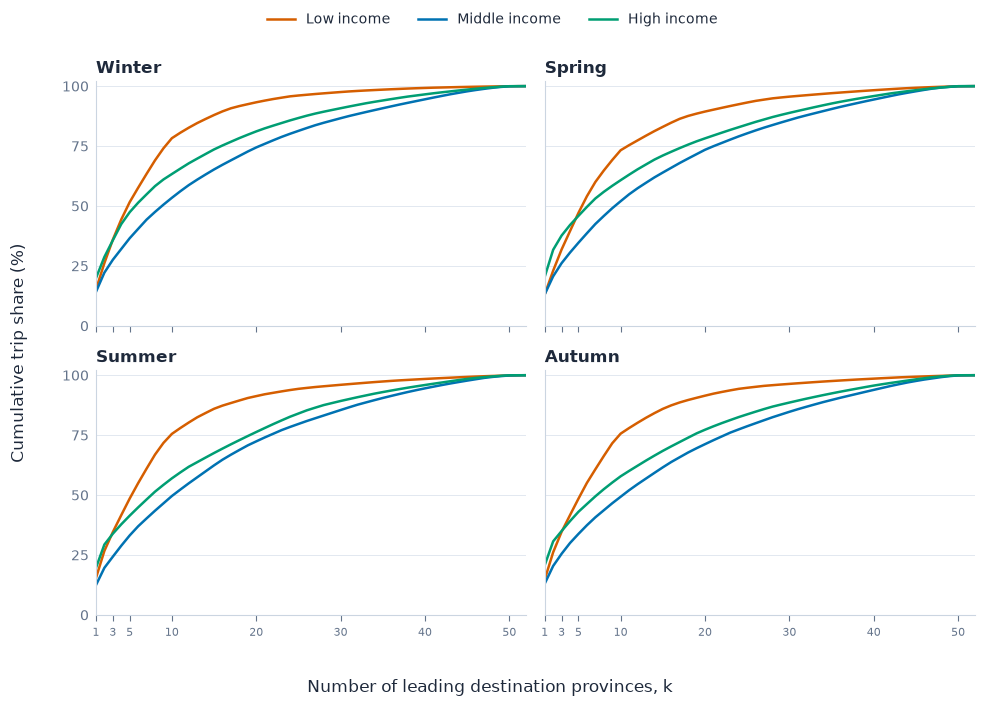

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for axis, season in zip(axes.flat, MAIN):
    for index, group in enumerate(GROUPS):
        axis.plot(np.arange(1, 53), main_curves[season][:, index], color=COLORS[group],
                  linewidth=1.8, label=LABELS[group])
    axis.set_title(season.title(), loc="left", fontweight="bold")
    axis.set(xlim=(1, 52), ylim=(0, 102), yticks=[0, 25, 50, 75, 100], xticks=[1, 3, 5, 10, 20, 30, 40, 50])
    style_axes(axis)
    axis.tick_params(axis="x", labelsize=8, length=4, width=0.8, direction="out")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False)
fig.supxlabel("Number of leading destination provinces, k")
fig.supylabel("Cumulative trip share (%)")
fig.tight_layout(rect=(0.025, 0.025, 1, 0.94))
export_figure(fig, "concentration_curves")


### Reference cutoffs and rank similarity

The plot above is the primary concentration result. The following tables provide the appendix's exact CR1, CR3, CR5, and CR10 values and the three pairwise rank correlations.

In [17]:
concentration_results = pd.DataFrame.from_dict(main_metrics, orient="index").rename_axis("season")
concentration_reference = concentration_results[[
    f"CR{k}_{group}_pct" for k in [1, 3, 5, 10] for group in GROUPS
]]
rank_similarity = concentration_results[["rho_low_mid", "rho_low_high", "rho_mid_high"]]
for group in GROUPS:
    columns = [f"CR{k}_{group}_pct" for k in [1, 3, 5, 10]]
    show_summary(f"Appendix reference cutoffs — {LABELS[group]}", concentration_reference[columns].rename(
        columns={f"CR{k}_{group}_pct": f"CR{k} (%)" for k in [1, 3, 5, 10]}))
show_summary("Destination-rank similarity (Spearman correlation)", rank_similarity.rename(columns={
    "rho_low_mid": "Low–middle", "rho_low_high": "Low–high", "rho_mid_high": "Middle–high",
}), decimals=3)



Appendix reference cutoffs — Low income


,CR1 (%),CR3 (%),CR5 (%),CR10 (%)
season,,,,
winter,15.11,35.94,51.60,78.28
spring,13.09,31.85,47.12,73.25
summer,15.36,34.54,48.55,75.52
autumn,14.76,34.67,48.50,75.62



Appendix reference cutoffs — Middle income


,CR1 (%),CR3 (%),CR5 (%),CR10 (%)
season,,,,
winter,14.15,27.55,36.55,53.40
spring,13.14,26.13,34.67,51.99
summer,12.42,24.29,33.15,49.60
autumn,13.03,25.49,33.79,49.29



Appendix reference cutoffs — High income


,CR1 (%),CR3 (%),CR5 (%),CR10 (%)
season,,,,
winter,19.86,35.68,47.41,63.33
spring,20.46,37.65,45.88,60.75
summer,19.61,33.86,41.40,56.97
autumn,20.73,34.99,43.02,57.82



Destination-rank similarity (Spearman correlation)


,Low–middle,Low–high,Middle–high
season,,,
winter,0.535,0.151,0.787
spring,0.406,0.225,0.847
summer,0.566,0.228,0.847
autumn,0.548,0.202,0.840


## 3. Spatial reach

Compute trip-weighted mean, median, and quartile distances for all three income layers. Distances are straight-line distances between representative points of the departure and destination districts in EPSG:25830, in kilometres; they are not travelled route lengths.

The sample is the same inter-province population used in Section 2. Report each layer's distribution, since a single low–high difference does not describe the middle-income layer.

In [18]:
def quantiles(values, weights, qs=(.25,.5,.75)):
    order = np.argsort(values)
    cum = np.cumsum(np.asarray(weights)[order])
    return np.asarray(values)[order][np.searchsorted(cum, np.asarray(qs)*cum[-1], side="left")]


def distance_outcomes(frame):
    metrics, rows = {}, []
    for group in GROUPS:
        part = frame.loc[frame.group == group]
        total = part.n_trips.sum()
        mean = np.average(part.distance, weights=part.n_trips)
        q25, median, q75 = quantiles(part.distance.to_numpy(), part.n_trips.to_numpy())
        metrics[f"mean_km_{group}"] = mean
        metrics[f"median_km_{group}"] = median
        metrics[f"share_ge50km_{group}_pct"] = 100 * part.loc[part.distance >= 50, "n_trips"].sum() / total
        rows.append(dict(group=group, trip_weight=total, mean_km=mean,
                         q25_km=q25, median_km=median, q75_km=q75,
                         share_ge50km_pct=metrics[f"share_ge50km_{group}_pct"],
                         official_mean_km=part.trips_total_length_km.sum(min_count=1) / total))
    for first, second in [("low", "mid"), ("low", "high"), ("mid", "high")]:
        metrics[f"mean_gap_{second}_minus_{first}_km"] = metrics[f"mean_km_{second}"] - metrics[f"mean_km_{first}"]
    return metrics, rows


In [19]:
distance_rows = []
for season in MAIN:
    inter = load_week(season)
    metrics, rows = distance_outcomes(inter)
    main_metrics[season].update(metrics)
    distance_rows.extend({"season": season, **row} for row in rows)
    check_main_metrics(season, metrics)
    del inter
distance_statistics = pd.DataFrame(distance_rows)
print("Distance means, medians, threshold shares, and pairwise gaps match the final revision.")
distance_display = distance_statistics[["season", "group", "mean_km", "median_km", "q25_km", "q75_km"]].copy()
distance_display["group"] = distance_display.group.map(LABELS)
show_summary("Trip-weighted endpoint distances (km)", distance_display.rename(columns={
    "season": "Season", "group": "Income", "mean_km": "Mean", "median_km": "Median", "q25_km": "P25", "q75_km": "P75",
}), decimals=1)


Distance means, medians, threshold shares, and pairwise gaps match the final revision.

Trip-weighted endpoint distances (km)


,Season,Income,Mean,Median,P25,P75
0,winter,Low income,98.6,44.1,20.9,98.4
1,winter,Middle income,113.5,61.1,25.9,116.7
2,winter,High income,154.6,79.4,44.2,170.3
3,spring,Low income,117.7,61.5,24.4,117.5
4,spring,Middle income,115.6,62.9,27.6,122.4
5,spring,High income,175.1,91.7,55.5,240.7
6,summer,Low income,110.9,56.5,22.7,114.9
7,summer,Middle income,127.7,71.3,30.2,139.1
8,summer,High income,166.9,90.9,49.5,231.6
9,autumn,Low income,114.9,58.4,23.6,117.9


## 4. Income composition of arrivals

For each destination province, compare its arrival income mix with the national mix of inter-province trips in the same week. Jensen–Shannon divergence (JSD, in bits) measures this difference; normalized entropy describes mixing among the three layers. National summaries weight destinations by their incoming trip volume.

In the map, colour identifies the income layer with the largest positive destination-minus-national share difference. Saturation encodes JSD, with a common cap across the four weeks. The provincial display uses the mainland/Balearic extent; all 52 units enter the numerical results.

In [20]:
def composition(matrix):
    values = matrix.to_numpy()
    totals = values.sum(axis=1)
    national = values.sum(axis=0)/values.sum()
    mix = np.divide(values, totals[:, None], out=np.zeros_like(values), where=totals[:, None]>0)
    jsd = np.array([jensenshannon(row, national, base=2)**2 if total>0 else np.nan for row,total in zip(mix,totals)])
    entropy = -np.sum(np.where(mix>0, mix*np.log(np.maximum(mix,1e-300)), 0), axis=1)/np.log(3)
    out = pd.DataFrame({"node_id": matrix.index, "inbound_total": totals, "jsd_bits": jsd, "entropy_norm": entropy})
    for i,g in enumerate(GROUPS):
        out[g] = values[:,i]
        out[f"share_{g}"] = mix[:,i]
        out[f"overrepresentation_{g}"] = mix[:,i]/national[i]
        out[f"overrepresentation_{g}_pp"] = 100*(mix[:,i]-national[i])
    out["most_overrepresented"] = np.array(GROUPS)[np.argmax(mix-national, axis=1)]
    out.loc[totals==0,"most_overrepresented"] = None
    return out, float(np.nansum(jsd*totals)/totals.sum()), float(np.sum(entropy*totals)/totals.sum())


In [21]:
province_composition = {}
for season in MAIN:
    mix, jsd, entropy = composition(province_matrices[season])
    province_composition[season] = mix.assign(season=season)
    metrics = {"weighted_destination_jsd_bits": jsd, "weighted_mixing_entropy_norm": entropy}
    main_metrics[season].update(metrics)
    check_main_metrics(season, metrics)

main_columns = [column for column in reference_results.columns if column != "role"]
main_results = pd.DataFrame([
    {"season": season, **main_metrics[season]} for season in MAIN
])[ ["season", *main_columns] ]
selectivity_summary = main_results.set_index("season")[[
    "weighted_destination_jsd_bits", "weighted_mixing_entropy_norm"
]]
print("Destination JSD and mixing entropy match the final revision.")
show_summary("National summary of destination composition", selectivity_summary.rename(columns={
    "weighted_destination_jsd_bits": "Weighted JSD (bits)", "weighted_mixing_entropy_norm": "Weighted normalized entropy",
}), decimals=3)


Destination JSD and mixing entropy match the final revision.

National summary of destination composition


,Weighted JSD (bits),Weighted normalized entropy
season,,
winter,0.052,0.703
spring,0.049,0.729
summer,0.035,0.742
autumn,0.039,0.738


In [22]:
CITY_POINTS = {"Madrid": (-3.7038, 40.4168), "Barcelona": (2.1734, 41.3851),
               "Valencia": (-0.3763, 39.4699), "Sevilla": (-5.9845, 37.3891), "Bilbao": (-2.9350, 43.2630)}

def plot_composition_map(geography, id_column, composition_by_season, scale):
    display_geo = geography.to_crs(4326).copy()
    if scale == "district":
        canaries = display_geo.province_code.isin(["35", "38"])
        display_geo.loc[canaries, "geometry"] = display_geo.loc[canaries, "geometry"].map(
            lambda polygon: translate(polygon, xoff=10.8, yoff=7.4))
    all_values = pd.concat(composition_by_season.values(), ignore_index=True)
    cap = max(float(all_values.jsd_bits.quantile(0.98)), 1e-8)

    def fill_color(row):
        if pd.isna(row.most_overrepresented) or pd.isna(row.jsd_bits):
            return "#E5E5E5"
        strength = 0.2 + 0.8 * np.clip(row.jsd_bits / cap, 0, 1)
        return to_hex(1 - strength + strength * np.array(to_rgb(COLORS[row.most_overrepresented])))

    fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
    for panel_index, (axis, season) in enumerate(zip(axes.flat, MAIN)):
        values = composition_by_season[season][["node_id", "most_overrepresented", "jsd_bits"]]
        mapped = display_geo.merge(values, left_on=id_column, right_on="node_id", how="left", validate="one_to_one")
        mapped.plot(ax=axis, color=mapped.apply(fill_color, axis=1).tolist(), edgecolor="#A0A0A0",
                    linewidth=0.06 if scale == "district" else 0.3)
        axis.set(xlim=(-10.3, 4.8), ylim=(34, 44.5))
        axis.set_axis_off()
        axis.set_title(f"{'ABCD'[panel_index]}. {season.title()}", loc="left", fontsize=11, fontweight="bold")
        for city, (longitude, latitude) in CITY_POINTS.items():
            axis.scatter(longitude, latitude, color="black", s=10, zorder=5)
            axis.text(longitude + 0.08, latitude + 0.08, city, fontsize=6.5, zorder=6)
    legend = [Patch(facecolor=COLORS[group], label=f"{LABELS[group]} overrepresented") for group in GROUPS]
    legend.append(Patch(facecolor="#E5E5E5", label="No retained arrivals"))
    fig.legend(handles=legend, loc="lower center", ncol=4, frameon=False, fontsize=8)
    fig.suptitle(f"Income composition of arrivals at destination {scale}s", fontsize=12)
    formats = ("png",) if scale == "district" else ("pdf", "png")
    name = "district_income_overrepresentation" if scale == "district" else "destination_selectivity"
    export_figure(fig, name, formats=formats, dpi=300)


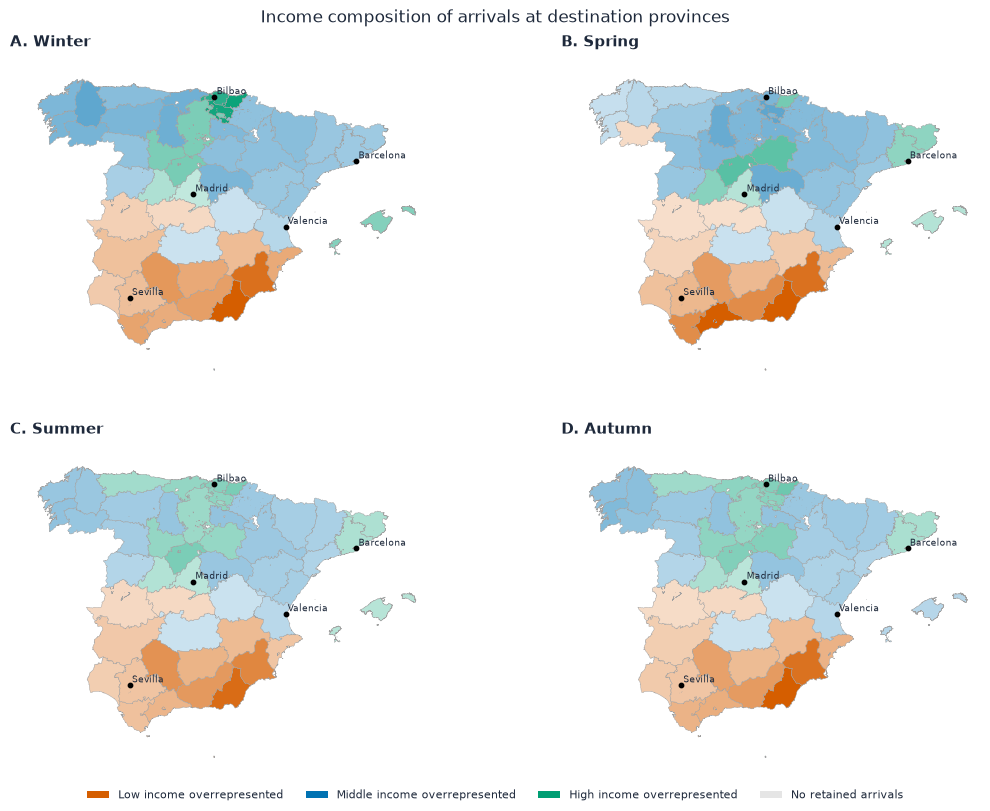

In [23]:
plot_composition_map(province_geo, "province_code", province_composition, "province")


### Destinations with the largest income overrepresentation

Rank provinces by their positive share difference from the national income mix, in percentage points. These appendix tables describe arrival composition, whereas Section 2 ranks provinces by the volume of each layer's trips.

In [24]:
top_rows = []
province_names = province_geo.set_index("province_code")
name_column = next((column for column in ["name", "province_name", "nombre"] if column in province_names), None)
for season in MAIN:
    composition_table = province_composition[season]
    national = province_matrices[season].sum() / province_matrices[season].to_numpy().sum()
    for group in GROUPS:
        top = composition_table.nlargest(10, f"overrepresentation_{group}_pp")
        for rank, row in enumerate(top.to_dict("records"), start=1):
            top_rows.append({
                "season": season, "group": group, "rank": rank, "province_code": row["node_id"],
                "province": province_names.loc[row["node_id"], name_column] if name_column else row["node_id"],
                "jsd_bits": row["jsd_bits"], "destination_share_pct": 100 * row[f"share_{group}"],
                "national_share_pct": 100 * national[group],
                "overrepresentation_pp": row[f"overrepresentation_{group}_pp"],
            })
top_destinations = pd.DataFrame(top_rows)
for group in GROUPS:
    print(LABELS[group])
    display(top_destinations.loc[top_destinations.group == group].round(3))


Low income


,season,group,rank,province_code,province,jsd_bits,destination_share_pct,national_share_pct,overrepresentation_pp
0,winter,low,1,04,Almeria,0.207,67.226,17.561,49.664
1,winter,low,2,30,Murcia,0.132,55.664,17.561,38.103
2,winter,low,3,14,Cordoba,0.085,46.296,17.561,28.734
3,winter,low,4,18,Granada,0.076,45.321,17.561,27.760
4,winter,low,5,11,Cadiz,0.071,43.185,17.561,25.624
5,winter,low,6,23,Jaen,0.064,41.450,17.561,23.888
6,winter,low,7,03,Alicante/Alacant,0.064,41.282,17.561,23.721
7,winter,low,8,51,Ceuta,0.063,41.275,17.561,23.714
8,winter,low,9,29,Malaga,0.061,40.577,17.561,23.016
9,winter,low,10,41,Sevilla,0.038,36.825,17.561,19.264


Middle income


,season,group,rank,province_code,province,jsd_bits,destination_share_pct,national_share_pct,overrepresentation_pp
10,winter,mid,1,27,Lugo,0.082,87.266,63.376,23.890
11,winter,mid,2,36,Pontevedra,0.063,86.131,63.376,22.755
12,winter,mid,3,32,Ourense,0.065,85.551,63.376,22.175
13,winter,mid,4,15,A Coruna,0.060,83.514,63.376,20.138
14,winter,mid,5,12,Castellon/Castello,0.041,83.484,63.376,20.108
15,winter,mid,6,43,Tarragona,0.040,81.211,63.376,17.835
16,winter,mid,7,26,La Rioja,0.057,80.710,63.376,17.334
17,winter,mid,8,49,Zamora,0.045,80.109,63.376,16.733
18,winter,mid,9,19,Guadalajara,0.061,79.965,63.376,16.589
19,winter,mid,10,24,Leon,0.061,79.861,63.376,16.485


High income


,season,group,rank,province_code,province,jsd_bits,destination_share_pct,national_share_pct,overrepresentation_pp
20,winter,high,1,20,Gipuzkoa,0.145,54.995,19.063,35.932
21,winter,high,2,01,Araba/Alava,0.140,54.565,19.063,35.502
22,winter,high,3,48,Bizkaia,0.121,48.846,19.063,29.784
23,winter,high,4,40,Segovia,0.064,39.390,19.063,20.328
24,winter,high,5,47,Valladolid,0.060,33.000,19.063,13.937
25,winter,high,6,07,Illes Balears,0.054,31.775,19.063,12.712
26,winter,high,7,09,Burgos,0.061,31.716,19.063,12.654
27,winter,high,8,05,Avila,0.023,27.731,19.063,8.669
28,winter,high,9,28,Madrid,0.008,26.166,19.063,7.103
29,winter,high,10,34,Palencia,0.071,25.360,19.063,6.297


## 5. Geographic benchmark

The previous sections describe observed differences. This benchmark asks how much of those differences can be reproduced if income layers have the same destination proportions when they share a departure district and recorded residence province.

### Construction and conserved trip volumes

Within each **departure district × recorded residence province** combination, retain each category's inter-province trip volume and give all categories the pooled destination-district proportions of that combination:

$$E_{ordg}=V_{org}\frac{V_{ord}}{V_{or}}.$$

Departure and residence remain distinct because a trip need not begin at home. Aggregate expected district flows to the same provinces as observed flows. Observed and expected comparisons use exactly the same known-residence sample. Repeat the comparison on combinations containing positive volume in all three categories; this changes the selected trip population and is reported separately.

The benchmark is descriptive standardization, not a causal estimate. Both the category-volume and pooled-destination margins must be conserved.

In [25]:
def benchmark(f, support):
    """E_sdg = V_sg V_sd / V_s; condition on departure district and residence.

    The universe is observed pooled s,d pairs crossed with income bands present
    in that stratum. This includes zero observed group cells without densifying
    every possible district pair. Both benchmark margins are checked explicitly.
    """
    if support not in {"known_residence", "common3_positive"}:
        raise ValueError(f"Unsupported benchmark sample: {support}")
    keys=["id_origin","residence_province"]
    known=f.dropna(subset=["residence_province"])
    margins=known.groupby(keys+["group"], observed=True).n_trips.sum().unstack(fill_value=0).reindex(columns=GROUPS,fill_value=0)
    mask=pd.Series(True,index=margins.index)
    if support=="common3_positive": mask=(margins>0).all(axis=1)
    keep=margins.loc[mask].stack().rename("group_volume").reset_index()
    chosen=known.merge(margins.loc[mask].reset_index()[keys],on=keys)
    pooled=chosen.groupby(keys+["id_destination"],as_index=False).agg(pooled_weight=("n_trips","sum"),distance=("distance","first"),op=("op","first"),dp=("dp","first"))
    pooled=pooled.merge(margins.sum(axis=1).rename("stratum_volume").reset_index(),on=keys)
    expected=pooled.merge(keep,on=keys)
    expected["n_trips"]=expected.group_volume*expected.pooled_weight/expected.stratum_volume
    # official distances are not used for expected geometric distance summaries.
    expected["trips_total_length_km"]=np.nan
    check_close(expected.groupby(keys+["group"]).n_trips.sum().sort_index(),
        chosen.groupby(keys+["group"]).n_trips.sum().reindex(expected.groupby(keys+["group"]).n_trips.sum().index,fill_value=0).sort_index(),"benchmark group margins")
    check_close(expected.groupby(keys+["id_destination"]).n_trips.sum().sort_index(),
        chosen.groupby(keys+["id_destination"]).n_trips.sum().sort_index(),"benchmark pooled OD margins")
    return chosen, expected, dict(support_sample=support,n_strata=int(mask.sum()),
        retained_trip_pct=100*chosen.n_trips.sum()/known.n_trips.sum(),
        known_residence_pct=100*known.n_trips.sum()/f.n_trips.sum())


### Observed and expected results

Apply the same concentration, ranking, distance, and composition measures to both flows. The primary comparison uses all trips with known residence. The additional common-support comparison retains only departure–residence combinations with positive trip volume in every income layer; its retention and results are inspected below.

In [26]:
def outcomes(f):
    matrix = destination_matrix(f)
    curves = concentration(matrix)
    comp, jsd, ent = composition(matrix)
    metrics = dict(weighted_destination_jsd_bits=jsd, weighted_mixing_entropy_norm=ent)
    distance_rows=[]
    for i,g in enumerate(GROUPS):
        part=f.loc[f.group==g]
        total=part.n_trips.sum()
        mean=np.average(part.distance, weights=part.n_trips)
        q25,median,q75=quantiles(part.distance.to_numpy(),part.n_trips.to_numpy())
        metrics[f"mean_km_{g}"]=mean
        metrics[f"median_km_{g}"]=median
        metrics[f"share_ge50km_{g}_pct"]=100*part.loc[part.distance>=50,"n_trips"].sum()/total
        for k in [1,3,5,10]: metrics[f"CR{k}_{g}_pct"]=curves[k-1,i]
        distance_rows.append(dict(group=g,trip_weight=total,mean_km=mean,q25_km=q25,median_km=median,q75_km=q75,
            share_ge50km_pct=metrics[f"share_ge50km_{g}_pct"], official_mean_km=part.trips_total_length_km.sum(min_count=1)/total))
    for a,b in [("low","mid"),("low","high"),("mid","high")]:
        metrics[f"rho_{a}_{b}"]=spearmanr(matrix[a],matrix[b]).statistic
        metrics[f"mean_gap_{b}_minus_{a}_km"]=metrics[f"mean_km_{b}"]-metrics[f"mean_km_{a}"]
    metrics["rank_gap_mid_high_minus_low_high"]=metrics["rho_mid_high"]-metrics["rho_low_high"]
    metrics["CR10_gap_low_minus_high_pp"]=metrics["CR10_low_pct"]-metrics["CR10_high_pct"]
    return metrics, matrix, curves, comp, distance_rows


In [27]:
benchmark_rows, support_rows = [], []
benchmark_curves = {}
for season in MAIN:
    print(f"\n{season.upper()}", flush=True)
    inter = load_week(season)
    week_benchmark_rows = []
    for support in ["known_residence", "common3_positive"]:
        observed, expected, support_info = benchmark(inter, support)
        observed_metrics, _, observed_curves, _, _ = outcomes(observed)
        expected_metrics, _, expected_curves, _, _ = outcomes(expected)
        benchmark_curves[(season, support, "observed")] = observed_curves
        benchmark_curves[(season, support, "expected")] = expected_curves
        support_rows.append({"season": season, **support_info})
        benchmark_rows.extend({
            "season": season, "support_sample": support, "metric": metric,
            "observed": value, "expected": expected_metrics[metric],
            "residual": value - expected_metrics[metric],
        } for metric, value in observed_metrics.items())
        gap_discrepancies = [
            np.max(np.abs((observed_curves[:, GROUPS.index(first)] - observed_curves[:, GROUPS.index(second)])
                          - (expected_curves[:, GROUPS.index(first)] - expected_curves[:, GROUPS.index(second)])))
            for first, second in PAIRS
        ]
        week_benchmark_rows.append({
            "Benchmark sample": "Known residence" if support == "known_residence" else "All three categories present",
            "Departure–residence combinations": support_info["n_strata"],
            "Retained known-residence weight (%)": support_info["retained_trip_pct"],
            "Maximum curve-gap discrepancy (pp)": max(gap_discrepancies),
        })
        del observed, expected
    print(f"Known residence covers {support_info['known_residence_pct']:.2f}% of inter-province trip weight.")
    show_summary("Benchmark agreement across all three income pairs and all 52 cutoffs", pd.DataFrame(week_benchmark_rows))

    del inter
    gc.collect()

residence_metrics = pd.DataFrame(benchmark_rows)
residence_support = pd.DataFrame(support_rows)
reference_benchmark = pd.read_csv(REFERENCE_DIR / "residence_metrics.csv").set_index(
    ["season", "support_sample", "metric"]
)
for row in residence_metrics.to_dict("records"):
    key = (row["season"], row["support_sample"], row["metric"])
    for state in ["observed", "expected"]:
        check_close(row[state], reference_benchmark.loc[key, state], f"benchmark {key}: {state}")
for curves in benchmark_curves.values():
    assert np.all(np.diff(curves, axis=0) >= -1e-9)
    check_close(curves[-1], 100, "benchmark concentration endpoint")
print("Benchmark margins, full-curve endpoints, and observed/expected reference metrics: passed.")



WINTER


Known residence covers 100.00% of inter-province trip weight.

Benchmark agreement across all three income pairs and all 52 cutoffs


,Benchmark sample,Departure–residence combinations,Retained known-residence weight (%),Maximum curve-gap discrepancy (pp)
0,Known residence,69857,100.00,0.33
1,All three categories present,6799,61.72,0.75



SPRING


Known residence covers 100.00% of inter-province trip weight.

Benchmark agreement across all three income pairs and all 52 cutoffs


...

,Benchmark sample,Departure–residence combinations,Retained known-residence weight (%),Maximum curve-gap discrepancy (pp)
0,Known residence,93512,100.00,0.50
1,All three categories present,10476,67.81,0.78



AUTUMN


Known residence covers 100.00% of inter-province trip weight.

Benchmark agreement across all three income pairs and all 52 cutoffs


,Benchmark sample,Departure–residence combinations,Retained known-residence weight (%),Maximum curve-gap discrepancy (pp)
0,Known residence,91038,100.00,0.40
1,All three categories present,10535,66.16,0.63


Benchmark margins, full-curve endpoints, and observed/expected reference metrics: passed.


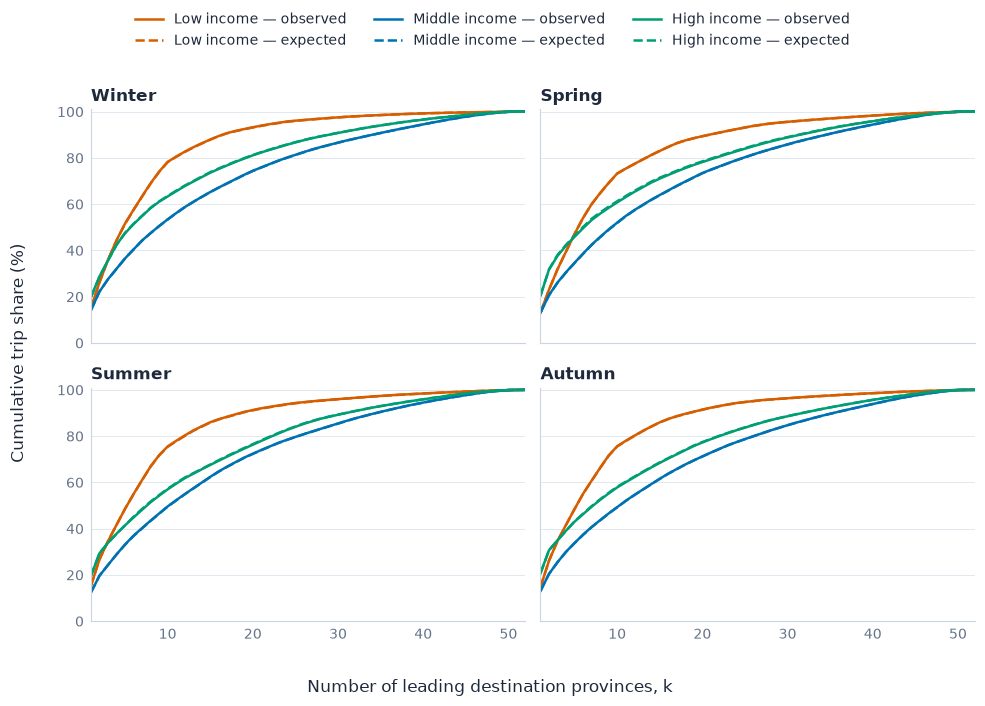

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for axis, season in zip(axes.flat, MAIN):
    for index, group in enumerate(GROUPS):
        for state, line_style in [("observed", "-"), ("expected", "--")]:
            curve = benchmark_curves[(season, "known_residence", state)]
            axis.plot(np.arange(1, 53), curve[:, index], color=COLORS[group], linestyle=line_style,
                      linewidth=1.8, label=f"{LABELS[group]} — {state}")
    axis.set_title(season.title(), loc="left", fontweight="bold")
    axis.set(xlim=(1, 52), ylim=(0, 101))
    style_axes(axis)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False)
fig.supxlabel("Number of leading destination provinces, k")
fig.supylabel("Cumulative trip share (%)")
fig.tight_layout(rect=(0.02, 0.02, 1, 0.9))
export_figure(fig, "concentration_observed_benchmark")


### Benchmark gaps across the complete curves

For each pair and week, the peak is the signed gap with the largest absolute magnitude. The benchmark is evaluated at that same cutoff. Maximum discrepancy compares observed and expected gaps over **all** cutoffs, not just at the peak. Common-support results remain separate from the full known-residence sample.

In [29]:
gap_rows = []
for season in MAIN:
    for support in ["known_residence", "common3_positive"]:
        observed = benchmark_curves[(season, support, "observed")]
        expected = benchmark_curves[(season, support, "expected")]
        for first, second in PAIRS:
            first_index, second_index = GROUPS.index(first), GROUPS.index(second)
            observed_gap = observed[:, first_index] - observed[:, second_index]
            expected_gap = expected[:, first_index] - expected[:, second_index]
            peak_index = int(np.argmax(np.abs(observed_gap)))
            gap_rows.append({
                "season": season, "support": support,
                "income_pair": f"{LABELS[first]} – {LABELS[second]}",
                "observed_peak_gap_pp": observed_gap[peak_index], "peak_k": peak_index + 1,
                "benchmark_at_peak_pp": expected_gap[peak_index],
                "maximum_discrepancy_pp": np.max(np.abs(observed_gap - expected_gap)),
            })
gap_summary = pd.DataFrame(gap_rows)
show_summary("Pairwise concentration peaks and benchmark discrepancies (pp)", gap_summary.loc[gap_summary.support == "known_residence"].drop(columns="support"))
benchmark_distances = residence_metrics.loc[
    (residence_metrics.support_sample == "known_residence") &
    residence_metrics.metric.isin([f"mean_km_{group}" for group in GROUPS]),
    ["season", "metric", "observed", "expected"],
]
show_summary("Mean endpoint distance (km): observed versus geographic benchmark", benchmark_distances, decimals=1)



Pairwise concentration peaks and benchmark discrepancies (pp)


,season,income_pair,observed_peak_gap_pp,peak_k,benchmark_at_peak_pp,maximum_discrepancy_pp
0,winter,Low income – High income,14.98,11,14.65,0.33
1,winter,Low income – Middle income,24.87,10,24.80,0.11
2,winter,High income – Middle income,10.91,6,11.14,0.28
6,spring,Low income – High income,12.50,10,11.97,0.58
7,spring,Low income – Middle income,21.26,10,21.34,0.12
8,spring,High income – Middle income,11.52,3,11.99,0.67
12,summer,Low income – High income,18.71,13,18.33,0.45
13,summer,Low income – Middle income,25.92,10,25.88,0.15
14,summer,High income – Middle income,9.72,2,9.73,0.50
18,autumn,Low income – High income,17.92,12,17.60,0.40



Mean endpoint distance (km): observed versus geographic benchmark


,season,metric,observed,expected
2,winter,mean_km_low,98.6,100.9
9,winter,mean_km_mid,113.5,113.7
16,winter,mean_km_high,154.6,151.9
64,spring,mean_km_low,117.7,119.1
71,spring,mean_km_mid,115.6,116.0
78,spring,mean_km_high,175.1,171.9
126,summer,mean_km_low,110.9,113.1
133,summer,mean_km_mid,127.7,128.2
140,summer,mean_km_high,166.9,164.3
188,autumn,mean_km_low,114.9,117.0


### Geographic overlap between income categories

The common-support check asks whether close benchmark agreement also appears when all three income layers occur within the same departure–residence combinations. It reduces the sample; compare observed and expected flows within that reduced population, rather than treating it as identical to the full main sample.

In [30]:
show_summary("Geographic overlap and sample retention", residence_support)
print("Largest curve-gap discrepancy (pp):")
display(gap_summary.groupby("support").maximum_discrepancy_pp.max().round(2))



Geographic overlap and sample retention


,season,support_sample,n_strata,retained_trip_pct,known_residence_pct
0,winter,known_residence,69857,100.00,100.0
1,winter,common3_positive,6799,61.72,100.0
2,spring,known_residence,80888,100.00,100.0
3,spring,common3_positive,8456,60.95,100.0
4,summer,known_residence,93512,100.00,100.0
5,summer,common3_positive,10476,67.81,100.0
6,autumn,known_residence,91038,100.00,100.0
7,autumn,common3_positive,10535,66.16,100.0


Largest curve-gap discrepancy (pp):


support
common3_positive    0.81
known_residence     0.67
Name: maximum_discrepancy_pp, dtype: float64

## 6. Sensitivity to spatial aggregation

The district and province measures use the **same inter-province trips**. Compare concentration by the percentage of the destination universe included, rather than an equal number of districts and provinces. This tests how the destination representation changes the results while holding the selected trip population fixed.

In [31]:
district_matrices, district_composition = {}, {}
scale_rows = []
for season in MAIN:
    inter = load_week(season)
    matrix = province_matrices[season]
    composition_table = province_composition[season]
    district_matrix = destination_matrix(inter, destination="id_destination", universe=sorted(mapping))
    district_matrices[season] = district_matrix
    district_mix, district_jsd, district_entropy = composition(district_matrix)
    district_composition[season] = district_mix.assign(season=season)
    province_category = composition_table.set_index("node_id").most_overrepresented
    active = district_mix.loc[district_mix.inbound_total > 0].copy()
    district_category_matches = active.most_overrepresented == active.node_id.map(mapping).map(province_category)
    agreement = 100 * np.average(district_category_matches, weights=active.inbound_total)
    for scale, destination_weights in [("district", district_matrix), ("province", matrix)]:
        _, jsd, entropy = composition(destination_weights)
        scale_rows.append({
            "season": season, "scale": scale, "n_destinations": len(destination_weights),
            "rho_low_high": spearmanr(destination_weights.low, destination_weights.high).statistic,
            "weighted_jsd_bits": jsd, "weighted_entropy": entropy,
            "weighted_category_agreement_pct": agreement,
        })


    del inter
scale_summary = pd.DataFrame(scale_rows)
reference_scale = pd.read_csv(REFERENCE_DIR / "scale_sensitivity.csv")
for row in scale_summary.to_dict("records"):
    previous = reference_scale.loc[
        (reference_scale.season == row["season"]) & (reference_scale.scale == row["scale"])
    ].iloc[0]
    check_close(row["rho_low_high"], previous.rho_low_high, "scale rank correlation")
    check_close(row["weighted_jsd_bits"], previous.weighted_destination_jsd_bits, "scale JSD")
    check_close(row["weighted_category_agreement_pct"], previous.weighted_overrepresentation_agreement_pct, "map agreement")
print("District/province rank correlations, JSD, and weighted category agreement match the final revision.")


District/province rank correlations, JSD, and weighted category agreement match the final revision.


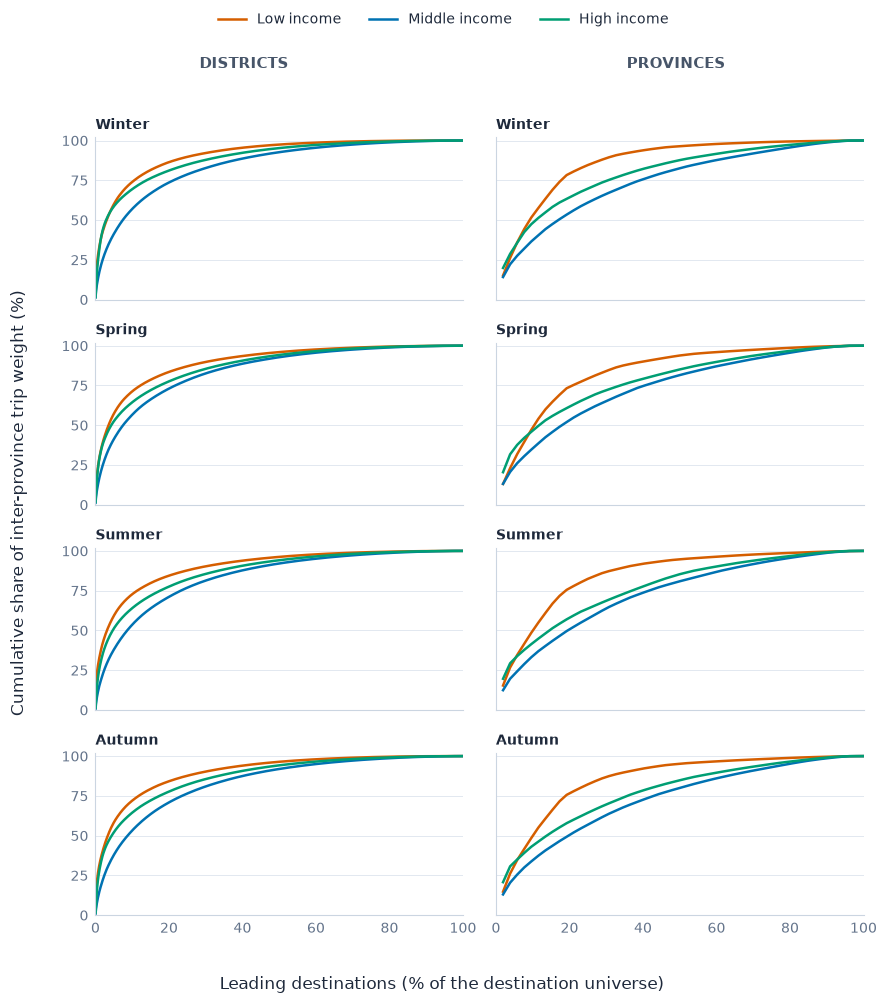

In [32]:
fig, axes = plt.subplots(4, 2, figsize=(9, 10), sharex=True, sharey=True)
for row_index, season in enumerate(MAIN):
    for column_index, matrix in enumerate([district_matrices[season], province_matrices[season]]):
        axis = axes[row_index, column_index]
        curves = concentration(matrix)
        for index, group in enumerate(GROUPS):
            axis.plot(100 * np.arange(1, len(matrix) + 1) / len(matrix), curves[:, index],
                      color=COLORS[group], linewidth=1.8, label=LABELS[group])
        axis.set_title(season.title(), loc="left", fontsize=10, fontweight="bold")
        axis.set(xlim=(0, 100), ylim=(0, 102), yticks=[0, 25, 50, 75, 100])
        style_axes(axis)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False)
fig.supxlabel("Leading destinations (% of the destination universe)")
fig.supylabel("Cumulative share of inter-province trip weight (%)")
fig.tight_layout(rect=(0.025, 0.02, 1, 0.90))
fig.text(0.28, 0.935, "DISTRICTS", ha="center", fontsize=11, fontweight="bold", color="#475569")
fig.text(0.76, 0.935, "PROVINCES", ha="center", fontsize=11, fontweight="bold", color="#475569")
export_figure(fig, "concentration_by_scale", dpi=220)


In [33]:
show_summary("Same inter-province trips, different destination scales", scale_summary[
    ["season", "scale", "n_destinations", "rho_low_high", "weighted_jsd_bits"]
].rename(columns={"season": "Season", "scale": "Destination scale", "n_destinations": "Destination units",
                  "rho_low_high": "Low–high Spearman correlation", "weighted_jsd_bits": "Weighted JSD (bits)"}), decimals=3)



Same inter-province trips, different destination scales


,Season,Destination scale,Destination units,Low–high Spearman correlation,Weighted JSD (bits)
0,winter,district,3743,0.250,0.102
1,winter,province,52,0.151,0.052
2,spring,district,3743,0.361,0.096
3,spring,province,52,0.225,0.049
4,summer,district,3743,0.370,0.082
5,summer,province,52,0.228,0.035
6,autumn,district,3743,0.354,0.088
7,autumn,province,52,0.202,0.039


### District arrival composition and agreement with province categories

The district map uses the same colour meanings as the provincial map in Section 4. The Canary Islands are repositioned for display only. Category agreement measures the share of incoming trip weight received by districts whose most-overrepresented income layer matches their province's layer; it is not the fraction of districts with matching labels.

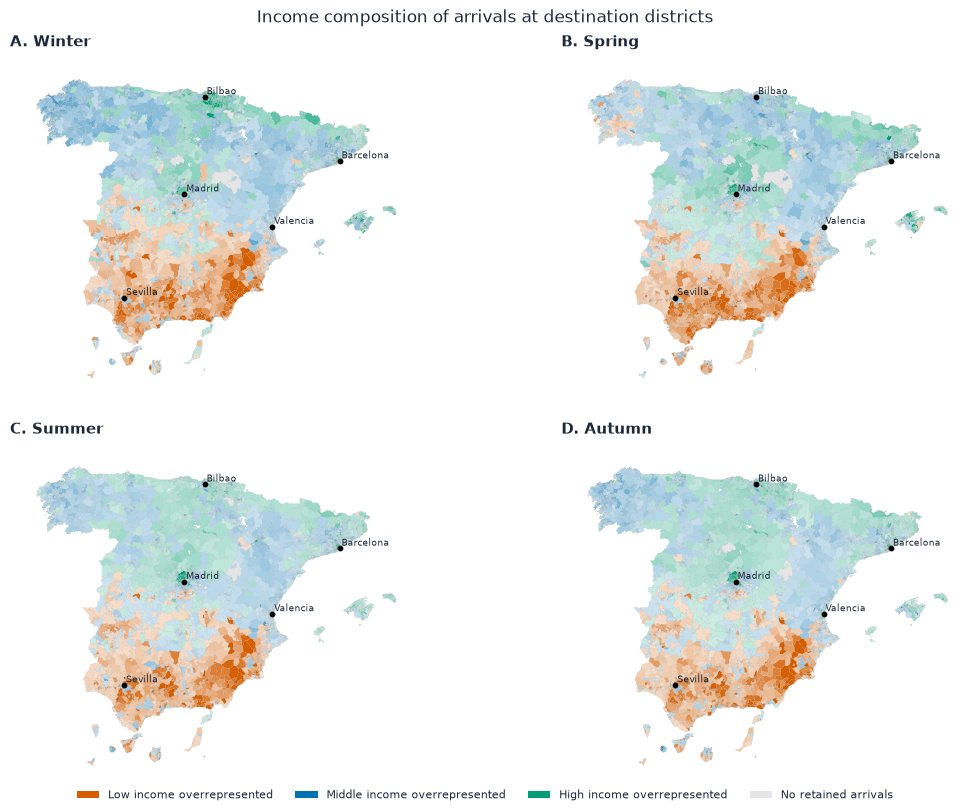

In [34]:
plot_composition_map(district_geo.reset_index(), "district_id", district_composition, "district")


In [35]:
map_agreement = scale_summary.loc[scale_summary.scale == "district", ["season", "weighted_category_agreement_pct"]].copy()
map_agreement["weighted_category_disagreement_pct"] = 100 - map_agreement.weighted_category_agreement_pct
show_summary("District–province category agreement, weighted by incoming trips (%)", map_agreement.rename(columns={
    "season": "Season", "weighted_category_agreement_pct": "Agreement (%)",
    "weighted_category_disagreement_pct": "Disagreement (%)",
}), decimals=1)



District–province category agreement, weighted by incoming trips (%)


,Season,Agreement (%),Disagreement (%)
0,winter,64.1,35.9
2,spring,63.9,36.1
4,summer,61.5,38.5
6,autumn,59.8,40.2


## 7. Export and interpretation

The files below contain the main and appendix results; they are recomputed by this notebook, not copied from prior tables. Full concentration trajectories and benchmark curves are saved so that individual cutoffs do not become the sole basis of interpretation.

The broad concentration pattern is shared across intermediate cutoffs at both scales, while the gaps and local arrival compositions depend on aggregation. Close benchmark agreement means that much of the national differentiation is reproduced under shared conditional destination proportions; it does not identify individual income effects. Four selected weeks do not establish general seasonal effects.

In [36]:
concentration_rows = [
    {"season": season, "group": group, "k": k + 1, "share_pct": curves[k, index]}
    for season, curves in main_curves.items()
    for index, group in enumerate(GROUPS) for k in range(52)
]
benchmark_curve_rows = [
    {"season": season, "support": support, "state": state, "group": group,
     "k": k + 1, "share_pct": curves[k, index]}
    for (season, support, state), curves in benchmark_curves.items()
    for index, group in enumerate(GROUPS) for k in range(52)
]
outputs = {
    "processing_audit": processing_audit, "flow_accounting": flow_accounting,
    "main_results": main_results, "concentration_reference": concentration_reference.reset_index(),
    "rank_similarity": rank_similarity.reset_index(), "distance_statistics": distance_statistics,
    "destination_composition": pd.concat(province_composition.values(), ignore_index=True),
    "district_destination_composition": pd.concat(district_composition.values(), ignore_index=True),
    "top10_income_overrepresentation": top_destinations,
    "concentration_curves": pd.DataFrame(concentration_rows),
    "full_concentration_curves": pd.DataFrame(benchmark_curve_rows),
    "concentration_gap_benchmark_summary": gap_summary,
    "residence_metrics": residence_metrics, "residence_support": residence_support,
    "scale_sensitivity": scale_summary, "weighted_map_agreement": map_agreement,
}
for name, table in outputs.items():
    table.to_csv(TABLE_DIR / f"{name}.csv", index=False)
(OUTPUT_DIR / "network_audits.json").write_text(json.dumps(network_audits, indent=2, default=str))
notebook_provenance = {
    "manuscript": "the revised paper", "windows": WINDOWS, "input_provenance": str(PIPELINE_OUTPUT / "provenance.json"),
    "input_package_sha256": provenance["package_sha256"], "installed_package_version": psm.__version__,
    "recorded_input_package_version": provenance["package_version"],
    "created_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "sample": provenance["sample"], "distance_method": provenance["distance_method"],
    "benchmark_supports": ["known_residence", "common3_positive"],
}
(OUTPUT_DIR / "provenance.json").write_text(json.dumps(notebook_provenance, indent=2))
display(pd.DataFrame({"Table": outputs.keys(), "Rows": [len(table) for table in outputs.values()]}))
print("Tables:", TABLE_DIR)
print("Figures:", FIGURE_DIR)


,Table,Rows
0,processing_audit,4
1,flow_accounting,4
2,main_results,4
3,concentration_reference,4
4,rank_similarity,4
5,distance_statistics,12
6,destination_composition,208
7,district_destination_composition,14972
8,top10_income_overrepresentation,120
9,concentration_curves,624


Tables: outputs/paper_revision/tables
Figures: outputs/paper_revision/figures
